# M01 概覽 | 量化一個模型，要回答哪三個問題

這一章第一次把模型量化成 int8。先不急著記 API，而是看清楚：量化到底要決定哪些事，
PT2E 又把這些決定放在圖上的哪裡。後面三本 notebook（M01-1～M01-3）再逐一動手驗證。

In [1]:
#| echo: false
import copy

import torch

from common.graph_utils import observer_nodes
from common.models import get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## 為什麼量化，以及量化要決定什麼

把 fp32 的運算換成 int8，weight 和 activation 佔的記憶體變成四分之一，
而手機、MCU、NPU 上的 int8 乘加通常比 fp32 快得多，也省電。

代價是：一個 fp32 tensor 的值要對應到只有 256 個格子的整數上。
每個要量化的 tensor 都需要一組對應規則（後面會看到，就是 scale 和 zero point 兩個數）。
一個模型有幾十、幾百個 tensor，於是有三個問題要回答：

1. **哪些 tensor 要量化？** 不是每條邊都要。例如 conv 後面緊接 relu 時，中間那個值不必存成 int8。
2. **每個 tensor 的 scale 和 zero point 是多少？** 這取決於那個 tensor 實際的數值範圍，要看資料才知道。
3. **量化的結果怎麼交給後端？** 最後真正跑 int8 kernel 的是 XNNPACK、ONNX Runtime 這類後端，它們要讀得懂。

PT2E（PyTorch 2 Export quantization）的回答是：先用 `torch.export` 把模型變成一張圖，三個問題都在這張圖上解決。

| 問題 | PT2E 的做法 | 在圖上的樣子 |
|---|---|---|
| 哪些 tensor 要量化 | **Quantizer** 在 node 上貼標註 | 沒有新 node，寫在 `node.meta` |
| scale／zero point 是多少 | **observer** 在校準時記錄數值範圍 | 邊上多出 observer node |
| 怎麼交給後端 | 把 observer 換成 **quantize／dequantize** | 邊上變成 q → dq 一對 node |

這張圖是 `torch.fx` 的 `GraphModule`。如果對 node、graph 這些名詞還不熟，
可以先讀〈[PyTorch FX 的 Graph／Node 一些基礎概念](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/)〉，
或本專案的 M00。

## PT2E 的四個步驟

實際寫程式時，這三件事拆成四個步驟，每一步是一個 API 呼叫。quantizer 在第 2 步傳進去：

| 步驟 | API | 對圖做了什麼 | 回答哪個問題 |
|---|---|---|---|
| 1. export | `torch.export.export` | 把 `nn.Module` 變成 ATen op 組成的 fx 圖 | （準備好要改的圖） |
| 2. prepare | `prepare_pt2e(圖, quantizer)` | 依 quantizer 的標註，在要量化的邊上插 observer | 哪些 tensor 要量化 |
| 3. calibrate | 直接呼叫圖 | 餵代表性資料，observer 記下數值範圍；圖本身不變 | scale／zero point 是多少 |
| 4. convert | `convert_pt2e(圖)` | 把 observer 換成 quantize／dequantize node | 怎麼交給後端 |

四步裡只有 prepare 和 convert 會改圖。M01-1 把這四步在一個訓練好的模型上走一遍。

## 先看一個例子：conv → relu

最小的例子：一個 conv 接一個 relu。下圖是同一張圖在 export、prepare、convert 之後的樣子（calibrate 不改圖，只更新 observer 裡的統計，所以沒有單獨畫），第一個 row 是 export 與 prepare，第二個 row 是 convert：

- **export**：只有 `conv2d` 和 `relu`，weight 寫在 conv 底下的 `‹…›` 裡。
- **prepare**：quantizer 標了三個地方要量化：輸入 `x`、conv 的 weight、relu 的輸出。`prepare_pt2e` 在這三處各插一個 observer（綠框）。
  conv 和 relu 之間**沒有** observer。
- **convert**：校準之後，每個 observer 換成一對 quantize → dequantize，上面寫著算好的 scale 和 zero point。
  weight 已經存成 int8 常數，只剩 dequantize。

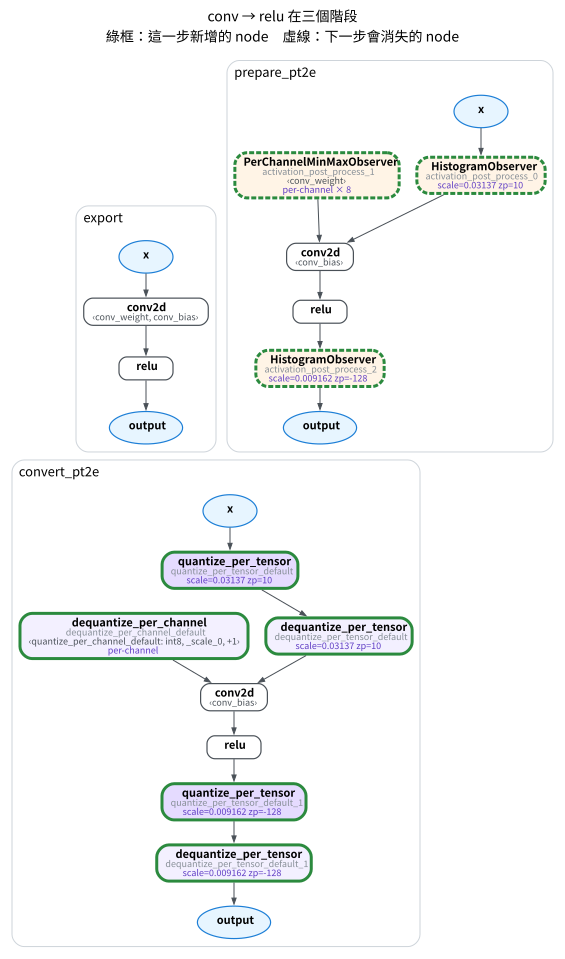

In [2]:
#| echo: false
model = get_model("conv_relu").eval()
ex = (torch.randn(4, 3, 16, 16),)
gm = export_module(model, ex)
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
with torch.no_grad():
    for _ in range(8):
        prepared(torch.randn(4, 3, 16, 16))
converted = convert_pt2e(copy.deepcopy(prepared))
assert len(observer_nodes(prepared)) == 3
draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")],
            title="conv → relu 在三個階段")

這張圖已經回答了三個問題：標註決定**哪裡**有 observer；observer 看過資料後決定 **scale／zero point**；
convert 把結果寫成後端看得懂的 **q/dq**。接下來把用到的名詞一個一個定義清楚。

## 定義

### affine 量化：scale 與 zero point

把實數 $x$ 對應到整數 $q$ 的規則是：

$$
q = \mathrm{clamp}\Big(\mathrm{round}\big(\tfrac{x}{s}\big) + z,\ q_{\min},\ q_{\max}\Big) \tag{1}
$$

反過來，整數 $q$ 代表的實數是：

$$
\hat{x} = s\,(q - z) \tag{2}
$$

- $s$（**scale**）：一格整數代表多少實數，是正的 fp32。
- $z$（**zero point**）：實數 0 對應到哪個整數。有了它，0 一定能被精確表示（zero padding、relu 輸出的大量 0 都不失真）。
- $[q_{\min}, q_{\max}]$：整數範圍。int8 activation 是 $[-128, 127]$。

先量化再反量化，$\hat{x}$ 和 $x$ 的差就是**量化誤差**。只要 $x$ 落在可表示的範圍內，誤差不超過半格：
$|x - \hat{x}| \le s/2$。超出範圍的值會被 clamp，誤差就沒有上限。
所以選 $s$ 是一個取捨：範圍開大，clamp 少，但每格變粗；範圍開小，每格細，但容易 clamp。

### observer：從數值範圍算出 $s$ 與 $z$

**observer** 是插在圖上某條邊的小模組：forward 時原樣傳回輸入，順便記下看過的數值。
最簡單的 `MinMaxObserver` 只記最小值與最大值，再把範圍擴張到包含 0：
$x'_{\min} = \min(x_{\min}, 0)$、$x'_{\max} = \max(x_{\max}, 0)$，然後

$$
s = \frac{x'_{\max} - x'_{\min}}{q_{\max} - q_{\min}}, \qquad
z = q_{\min} - \mathrm{round}\Big(\frac{x'_{\min}}{s}\Big) \tag{3}
$$

weight 通常用**對稱**量化：固定 $z = 0$，整數範圍用 $[-127, 127]$，於是 $s = \max|x| / 127$。
再加上 **per-channel**：conv 的每個 output channel 各自算一個 $s$。

下面用 torchao 的 observer 實際算一次，和式 (3)、對稱公式手算的結果比對：

In [3]:
from common.pt2e import MinMaxObserver, PerChannelMinMaxObserver

x = torch.randn(1000) * 2 + 0.5
obs = MinMaxObserver(dtype=torch.int8, quant_min=-128, quant_max=127)
obs(x)
s, z = obs.calculate_qparams()
x_min, x_max = min(x.min().item(), 0.0), max(x.max().item(), 0.0)
s_hand = (x_max - x_min) / 255
z_hand = -128 - round(x_min / s_hand)

w = torch.randn(8, 3, 3, 3)
w_obs = PerChannelMinMaxObserver(ch_axis=0, dtype=torch.int8, quant_min=-127, quant_max=127,
                                 qscheme=torch.per_channel_symmetric)
w_obs(w)
w_s, w_z = w_obs.calculate_qparams()

assert torch.isclose(s, torch.tensor(s_hand)) and int(z) == z_hand
assert torch.allclose(w_s, w.abs().amax(dim=(1, 2, 3)) / 127) and not w_z.any()
table([["activation（MinMaxObserver）", f"s={float(s):.5f}, z={int(z)}", f"s={s_hand:.5f}, z={z_hand}"],
       ["weight（per-channel 對稱，第 0 個 channel）", f"s={float(w_s[0]):.5f}, z={int(w_z[0])}",
        f"s={float(w[0].abs().max() / 127):.5f}, z=0"]],
      ["", "observer 算的", "公式手算"])

,observer 算的,公式手算
activation（MinMaxObserver）,"s=0.05283, z=-7","s=0.05283, z=-7"
weight（per-channel 對稱，第 0 個 channel）,"s=0.01301, z=0","s=0.01301, z=0"


本專案用的 XNNPACKQuantizer，預設設定對 activation 用的是 `HistogramObserver`（這是 quantizer 設定的選擇，換一個 quantizer 可能不同）：它不直接拿 min/max，
而是挑一個讓量化誤差最小的範圍（M02 細講）；選定範圍之後，換算 $s$、$z$ 的方式和式 (3) 相同。

### Quantizer 與 annotation

**Quantizer** 是後端提供的物件，它只做一件事：走過整張圖，在要量化的 node 上寫下**標註**（annotation），
例如「conv 的第 0 個輸入用 int8 per-tensor、配 HistogramObserver；weight 用 int8 per-channel 對稱」。
它不改圖；`prepare_pt2e` 讀標註、插 observer。
為什麼由後端來寫？因為「哪些 op 可以融合、支援哪些量化方式」是後端的 kernel 決定的。

### quantize／dequantize 與 Q/DQ 圖

`convert_pt2e` 把每個 observer 換成兩個 node：`quantize_per_tensor`（式 1，fp32 → int8）
和 `dequantize_per_tensor`（式 2，int8 → fp32），$s$、$z$ 寫死在 node 的參數裡。
換完的圖稱為 **Q/DQ 圖**：每個 op 前面是 dq、後面是 q，op 本身還是 fp32 運算。
下圖在邊上標出 tensor 的型別（只寫 shape 的邊是 float32）：

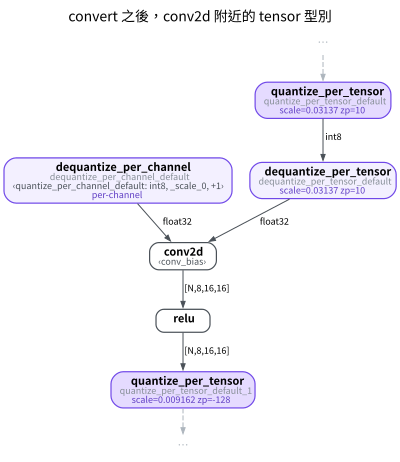

In [4]:
#| echo: false
draw(converted, focus=["conv2d"], hops=2, show_shapes=True, title="convert 之後，conv2d 附近的 tensor 型別")

q 的輸出是 int8，但 dq 又把它還原成 fp32 再交給 conv2d。Q/DQ 圖因此**不會比較快**，
它只是在數值上模擬了 int8：每個 q → dq 都把值吸附到最近的格子上。

那後端怎麼用它？以 conv 為例，輸入與 weight 都是式 (2) 的形式（weight 的 $z_w = 0$）：

$$
\sum_i \hat{w}_i \hat{x}_i = \sum_i s_w q_{w,i} \cdot s_x (q_{x,i} - z_x)
= s_w s_x \sum_i q_{w,i} (q_{x,i} - z_x) \tag{4}
$$

右邊的加總只有整數乘加，可以用 int8 × int8 → int32 累加完成；最後乘上 $s_w s_x$、再依輸出的 $s_y, z_y$ 量化回 int8。
所以後端只要在圖上認出「dq → conv → q」這個 pattern，就能把它換成一個 int8 conv kernel，
需要的 $s$、$z$ 全都寫在 q/dq node 上。（bias、relu 怎麼併進去是後端的細節，M07、M08 再看。）

## 用程式驗證：量化誤差不超過半格

用 convert 插進圖裡的同一組 op（`torch.ops.quantized_decomposed`）做一次 q → dq：

In [5]:
s, z = 0.02, -3
x = torch.linspace(-4, 4, 20001)  # 可表示範圍約 [-2.5, 2.6]，兩端故意超出
q = torch.ops.quantized_decomposed.quantize_per_tensor(x, s, z, -128, 127, torch.int8)
x_hat = torch.ops.quantized_decomposed.dequantize_per_tensor(q, s, z, -128, 127, torch.int8)

in_range = (x >= s * (-128 - z)) & (x <= s * (127 - z))
err = (x - x_hat).abs()
print(f"q 的 dtype：{q.dtype}，整數範圍 [{int(q.min())}, {int(q.max())}]")
print(f"範圍內的最大誤差 {float(err[in_range].max()):.5f}（s/2 = {s / 2}）")
print(f"範圍外（被 clamp）的最大誤差 {float(err[~in_range].max()):.3f}")
assert err[in_range].max() <= s / 2 + 1e-6

q 的 dtype：torch.int8，整數範圍 [-128, 127]
範圍內的最大誤差 0.01000（s/2 = 0.01）
範圍外（被 clamp）的最大誤差 1.500


## 小結與本章地圖

- 量化要回答三個問題：量化哪些 tensor、每個 tensor 的 $s$ 與 $z$、怎麼交給後端。
- PT2E 在 `torch.export` 的圖上依序回答：Quantizer 標註 → observer 校準 → convert 成 Q/DQ 圖。
- Q/DQ 圖只是數值上的模擬；真正的 int8 運算是後端認出 dq → op → q 之後換上的 kernel。

| notebook | 回答的問題 |
|---|---|
| [M01-1 最小 PTQ](01_minimal_ptq.ipynb) | 四個步驟走一遍，每一步圖怎麼變、精度掉多少 |
| [M01-2 prepare／convert 改了哪裡](02_graph_diff.ipynb) | observer 掛在哪些邊、skip connection 怎麼處理、quantizer 實際管了哪些 op |
| [M01-3 QuantizationConfig 的開關](03_config_matrix.ipynb) | per-channel、QAT、dynamic 各改變了什麼；per-channel 何時重要 |

這一章刻意跳過的：observer 的種類與 fake quant（M02）、quantizer 怎麼寫標註（M03）、BN 怎麼折進 conv（M04）、
後端怎麼把 Q/DQ 圖變成 int8 kernel（M07 起）。

## 參考資料

- PyTorch 官方教學：[PyTorch 2 Export Post Training Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quant_ptq.html)、
  [How to Write a Quantizer for PyTorch 2 Export Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quantizer.html)
- torchao 原始碼：[`torchao/quantization/pt2e/`](https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e)（本專案用 torchao 0.18）
- B. Jacob et al., [Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference](https://arxiv.org/abs/1712.05877), CVPR 2018：式 (1)～(4) 的 affine 量化與整數運算
- R. Krishnamoorthi, [Quantizing deep convolutional networks for efficient inference: A whitepaper](https://arxiv.org/abs/1806.08342), 2018：per-channel、對稱／非對稱的比較
- [PyTorch FX 的 Graph／Node 一些基礎概念](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/)：fx 圖的 node 與 graph